In [5]:
include("GodunovMethod.jl")

MovingGridsDynamicStep (generic function with 1 method)

In [6]:
using DataFrames
using PrettyTables

γ = BigFloat("1.4")
ε = BigFloat("1e-15")

Tests = DataFrame(
    Test = Int8[],
    ρₗ = BigFloat[],
    uₗ = BigFloat[],
    pₗ = BigFloat[],
    ρᵣ = BigFloat[],
    uᵣ = BigFloat[],
    pᵣ = BigFloat[],
    t = BigFloat[]
)

push!(Tests, [1 BigFloat("1.0") BigFloat("0.0") BigFloat("1.0") BigFloat("0.125") BigFloat("0.0") BigFloat("0.1") BigFloat("0.25")])
push!(Tests, [2 BigFloat("1.0") BigFloat("-2.0") BigFloat("0.4") BigFloat("1.0") BigFloat("2.0") BigFloat("0.4") BigFloat("0.15")])
push!(Tests, [3 BigFloat("1.0") BigFloat("0.0") BigFloat("1000.0") BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("0.012")])
push!(Tests, [4 BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("1.0") BigFloat("0.0") BigFloat("100.0") BigFloat("0.035")])
push!(Tests, [5 BigFloat("5.99924") BigFloat("19.5975") BigFloat("460.894") BigFloat("5.99242") BigFloat("-6.19633") BigFloat("46.0950") BigFloat("0.035")])

pretty_table(Tests;
    formatters = [fmt__printf("%.5f", [2, 3, 4, 5, 6, 7, 8])],
    style = TextTableStyle(; table_border = crayon"yellow"),
    fit_table_in_display_horizontally = false,
)

┌──────┬──────────┬──────────┬────────────┬──────────┬──────────┬───────────┬──────────┐
│ Test │       ρₗ │       uₗ │         pₗ │       ρᵣ │       uᵣ │        pᵣ │        t │
│ Int8 │ BigFloat │ BigFloat │   BigFloat │ BigFloat │ BigFloat │  BigFloat │ BigFloat │
├──────┼──────────┼──────────┼────────────┼──────────┼──────────┼───────────┼──────────┤
│    1 │  1.00000 │  0.00000 │    1.00000 │  0.12500 │  0.00000 │   0.10000 │  0.25000 │
│    2 │  1.00000 │ -2.00000 │    0.40000 │  1.00000 │  2.00000 │   0.40000 │  0.15000 │
│    3 │  1.00000 │  0.00000 │ 1000.00000 │  1.00000 │  0.00000 │   0.01000 │  0.01200 │
│    4 │  1.00000 │  0.00000 │    0.01000 │  1.00000 │  0.00000 │ 100.00000 │  0.03500 │
│    5 │  5.99924 │ 19.59750 │  460.89400 │  5.99242 │ -6.19633 │  46.09500 │  0.03500 │
└──────┴──────────┴──────────┴────────────┴──────────┴──────────┴───────────┴──────────┘


In [7]:
using Statistics
using Polynomials
using Plots

function loghloge(TestCase::Int64)

    default(:xlabel, "h")
    default(:legend, :bottomright)
    default(:xscale, :log10)
    default(:yscale, :log10)

    Wₗ = PrimVars(Tuple(Tests[TestCase, 2:4]))
    Wᵣ = PrimVars(Tuple(Tests[TestCase, 5:7]))
    t_max = Tests[TestCase, 8]
    max_h = BigFloat("0.04")
    min_h = BigFloat("0.01")

    CourantNumber = BigFloat("0.05")
    ε₁ = BigFloat("0.0002")
    ε₂ = BigFloat("0.0002")
    α = BigFloat("0.05")

    es = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )

    es2 = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )

    es3 = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )
    for h in logrange(max_h, min_h, 3)

        println("$h:")

        function BCₗ(t::BigFloat)
            return Wₗ
        end

        function BCᵣ(t::BigFloat)
            return Wᵣ
        end

        function IC(x::BigFloat)
            return x ≥ 0 ? Wᵣ : Wₗ
        end

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        ρs = BigFloat("0")
        us = BigFloat("0")
        ps = BigFloat("0")
        Es = BigFloat("0")

        W = W⁺(Wₗ, Wᵣ, γ, ε)
        a_max = 0
        for x in xs
            W_f = IC(x)
            a = sound_speed(W_f, γ)
            a_max = max(a, a_max)
        end
        Δt = find_Δt(BigFloat("0.125"), h, a_max, t_max)
        Ws = IC.(xs)
        pushfirst!(Ws, BCₗ(BigFloat(0)))
        push!(Ws, BCᵣ(BigFloat(0)))
        for t in BigFloat("0"):Δt:t_max
            Ws = GodunovMethodOneStep(Ws, xs, h, Δt, γ, ε)
            for x in eachindex(xs)
                W_exact = W(xs[x] / t)
                ρs += abs(Ws[x].ρ - W_exact.ρ)
                us += abs(Ws[x].u - W_exact.u)
                ps += abs(Ws[x].p - W_exact.p)
                Es += abs(Ws[x].p / (γ - 1) / Ws[x].ρ - W_exact.p / (γ - 1) / W_exact.ρ)
            end                
            pushfirst!(Ws, BCₗ(t))
            push!(Ws, BCᵣ(t))
        end
        pop!(Ws)
        popfirst!(Ws)

        push!(es, [h ρs*h*Δt us*h*Δt ps*h*Δt Es*h*Δt])

        println("    Non moving grid done")

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        ρs = BigFloat("0")
        us = BigFloat("0")
        ps = BigFloat("0")
        Es = BigFloat("0")

        Δt = t_max
        t = BigFloat(0)
        Ws = Vector{PrimVars}()
        for i in 1:(length(xs)-1)
            push!(Ws, IC((xs[i] + xs[i+1]) / 2))
        end
        ψs = ones(BigFloat, length(Ws))
        Δx = h
        Δy = xs[2:end] - xs[1:end-1]

        for i in 1:(length(xs)-1)
            h_inv = xs[i+1] - xs[i]
            a = sound_speed(Ws[i], γ)
            Δt = min(Δt, CourantNumber * h_inv / (a + abs(Ws[i].u)))
        end

        pushfirst!(Ws, BCₗ(BigFloat(0)))
        push!(Ws, BCᵣ(BigFloat(0)))

        while t < t_max
            Ws, ψs, xs = MovingGridsOneStep(Ws, ψs, xs, Δy, Δt, γ, ε, ε₁, ε₂, α)

            ρs1 = zeros(length(xs)-1)
            us1 = zeros(length(xs)-1)
            ps1 = zeros(length(xs)-1)
            Es1 = zeros(length(xs)-1)

            for x in 1:(length(xs)-1)
                W_exact = W((xs[x] + xs[x+1]) / t)
                ρs1[x] += abs(Ws[x].ρ - W_exact.ρ) * (xs[x+1] - xs[x]) * ψs[x]
                us1[x] += abs(Ws[x].u - W_exact.u) * (xs[x+1] - xs[x]) * ψs[x]
                ps1[x] += abs(Ws[x].p - W_exact.p) * (xs[x+1] - xs[x]) * ψs[x]
                Es1[x] += abs(Ws[x].p / (γ - 1) / Ws[x].ρ - W_exact.p / (γ - 1) / W_exact.ρ) * (xs[x+1] - xs[x]) * ψs[x]
            end
            
            ρs += sum(ρs1) * Δt
            us += sum(us1) * Δt
            ps += sum(ps1) * Δt
            Es += sum(Es1) * Δt

            t += Δt
            Δt = t_max - t
            for i in 1:(length(xs)-1)
                h_inv = xs[i+1] - xs[i]
                a = sound_speed(Ws[i], γ)
                Δt = min(Δt, CourantNumber * h_inv / (a + abs(Ws[i].u)))
            end

            pushfirst!(Ws, BCₗ(t))
            push!(Ws, BCᵣ(t))
        end

        pop!(Ws)
        popfirst!(Ws)

        push!(es2, [h ρs us ps Es])

        println("    Moving grid done")

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        ρs = BigFloat("0")
        us = BigFloat("0")
        ps = BigFloat("0")
        Es = BigFloat("0")

        Δt = t_max
        t = BigFloat(0)
        Ws = Vector{PrimVars}()
        for i in 1:(length(xs)-1)
            push!(Ws, IC((xs[i] + xs[i+1]) / 2))
        end
        ψs = ones(BigFloat, length(Ws))
        Δx = h
        Δy = xs[2:end] - xs[1:end-1]

        for i in 1:(length(xs)-1)
            h_inv = xs[i+1] - xs[i]
            a = sound_speed(Ws[i], γ)
            Δt = min(Δt, CourantNumber * h_inv / (a + abs(Ws[i].u)))
        end

        pushfirst!(Ws, BCₗ(BigFloat(0)))
        push!(Ws, BCᵣ(BigFloat(0)))

        while t < t_max
            Ws, ψs, xs = MovingGridsOneStep(Ws, ψs, xs, Δy, Δt, γ, ε, ε₁, ε₂, α)

            ρs1 = zeros(length(xs)-1)
            us1 = zeros(length(xs)-1)
            ps1 = zeros(length(xs)-1)
            Es1 = zeros(length(xs)-1)

            for x in 1:(length(xs)-1)
                W_exact = W((xs[x] + xs[x+1]) / t)
                ρs1[x] += abs(Ws[x].ρ - W_exact.ρ) * (xs[x+1] - xs[x]) * ψs[x]
                us1[x] += abs(Ws[x].u - W_exact.u) * (xs[x+1] - xs[x]) * ψs[x]
                ps1[x] += abs(Ws[x].p - W_exact.p) * (xs[x+1] - xs[x]) * ψs[x]
                Es1[x] += abs(Ws[x].p / (γ - 1) / Ws[x].ρ - W_exact.p / (γ - 1) / W_exact.ρ) * (xs[x+1] - xs[x]) * ψs[x]
            end
            
            ρs += sum(ρs1) * Δt
            us += sum(us1) * Δt
            ps += sum(ps1) * Δt
            Es += sum(Es1) * Δt

            t += Δt
            i = 2
            while i < length(xs)
                if xs[i + 1] - xs[i] > 1.5Δx
                    insert!(xs, i + 1, (xs[i + 1] + xs[i]) / 2)
                    insert!(Ws, i + 1, Ws[i])
                    Ws[i + 1] = W⁺(Ws[i + 1], W⁺(Ws[i + 1], Ws[i + 2], γ, ε)(BigFloat("0.0")), γ, ε)(BigFloat("0.0"))
                    Ws[i] = W⁺(W⁺(Ws[i - 1], Ws[i], γ, ε)(BigFloat("0.0")), Ws[i], γ, ε)(BigFloat("0.0"))
                    insert!(ψs, i + 1, ψs[i])
                    Δy[i] /= 2
                    insert!(Δy, i + 1, Δy[i])
                else
                    i += 1
                end
            end

            Δt = t_max - t
            for i in 1:(length(xs)-1)
                h_inv = xs[i+1] - xs[i]
                a = sound_speed(Ws[i], γ)
                Δt = min(Δt, CourantNumber * h_inv / (a + abs(Ws[i].u)))
            end

            pushfirst!(Ws, BCₗ(t))
            push!(Ws, BCᵣ(t))
        end

        pop!(Ws)
        popfirst!(Ws)

        push!(es3, [h ρs us ps Es])

        println("    Moving with birth nodes done")
    end

    p1 = fit(log10.(es[!, :hs]), log10.(es[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es[!, :hs]), log10.(es[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es[!, :hs]), log10.(es[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es[!, :hs]), log10.(es[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot(
        plot(es[!, :hs], es[!, :ρs_error], ylabel="Density error", label="p = "*p1_text),
        plot(es[!, :hs], es[!, :us_error], ylabel="Velocity error", label="p = "*p2_text),
        plot(es[!, :hs], es[!, :ps_error], ylabel="Pressure error", label="p = "*p3_text),
        plot(es[!, :hs], es[!, :Es_error], ylabel="Internal energy error", label="p = "*p4_text),
        layout=(2,2),
        margin=5Plots.mm,
        size=(800,600)
    )

    pretty_table(es3;
        formatters = [fmt__printf("%.4f", [1]), fmt__printf("%.2e", [2, 3, 4, 5])],
        style = TextTableStyle(; table_border = crayon"yellow"),
        fit_table_in_display_horizontally = false,
    )

    p1 = fit(log10.(es2[!, :hs]), log10.(es2[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es2[!, :hs]), log10.(es2[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es2[!, :hs]), log10.(es2[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es2[!, :hs]), log10.(es2[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot!(es2[!, :hs], es2[!, :ρs_error], subplot=1, label="p = "*p1_text, c=:red)
    plot!(es2[!, :hs], es2[!, :us_error], subplot=2, label="p = "*p2_text, c=:red)
    plot!(es2[!, :hs], es2[!, :ps_error], subplot=3, label="p = "*p3_text, c=:red)
    plot!(es2[!, :hs], es2[!, :Es_error], subplot=4, label="p = "*p4_text, c=:red)

    p1 = fit(log10.(es3[!, :hs]), log10.(es3[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es3[!, :hs]), log10.(es3[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es3[!, :hs]), log10.(es3[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es3[!, :hs]), log10.(es3[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot!(es3[!, :hs], es3[!, :ρs_error], subplot=1, label="p = "*p1_text, c=:blue)
    plot!(es3[!, :hs], es3[!, :us_error], subplot=2, label="p = "*p2_text, c=:blue),
    plot!(es3[!, :hs], es3[!, :ps_error], subplot=3, label="p = "*p3_text, c=:blue)
    plot!(es3[!, :hs], es3[!, :Es_error], subplot=4, label="p = "*p4_text, c=:blue)
end

loghloge (generic function with 1 method)

0.03999999999999999999999999999999999999999999999999999999999999999999999999999998:
    Non moving grid done
    Moving grid done
    Moving with birth nodes done
0.02000000000000000000000000000000000000000000000000000000000000000000000000000026:
    Non moving grid done
    Moving grid done
    Moving with birth nodes done
0.009999999999999999999999999999999999999999999999999999999999999999999999999999995:
    Non moving grid done
    Moving grid done
    Moving with birth nodes done
┌──────────┬──────────┬──────────┬──────────┬──────────┐
│       hs │ ρs_error │ us_error │ ps_error │ Es_error │
│ BigFloat │ BigFloat │ BigFloat │ BigFloat │ BigFloat │
├──────────┼──────────┼──────────┼──────────┼──────────┤
│   0.0400 │ 4.96e-02 │ 9.97e-02 │ 4.31e-02 │ 1.18e-01 │
│   0.0200 │ 3.60e-02 │ 7.04e-02 │ 3.23e-02 │ 9.07e-02 │
│   0.0100 │ 2.63e-02 │ 5.12e-02 │ 2.51e-02 │ 6.74e-02 │
└──────────┴──────────┴──────────┴──────────┴──────────┘


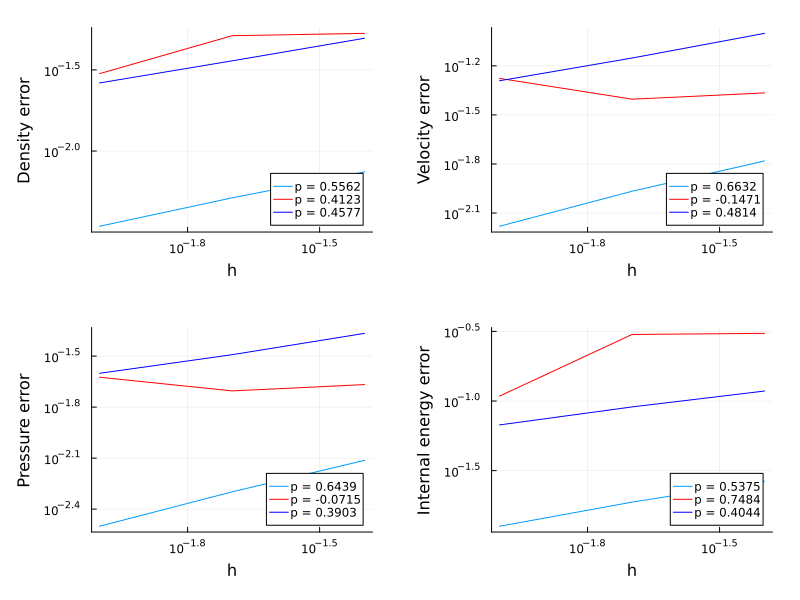

In [8]:
loghloge(1)